# Analisis Keranjang Pasar dengan Association Rule - Online Retail

Notebook ini menerapkan Association Rule Mining pada dataset Online Retail untuk menemukan pola produk yang sering dibeli bersama. Alur kerja mengikuti tugas Week 9: impor dataset, eksplorasi dan pembersihan, pembentukan transaksi berbasis invoice, one-hot encoding, penerapan FP-Growth, evaluasi aturan, dan penyusunan bahan laporan.

> Notebook ini disusun oleh Benedictus Ryu Gunawan (5054251001) untuk Tugas Week 9 - Association Rule.

# Import Library

In [1]:
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

warnings.filterwarnings("ignore")

In [2]:
DATA_RELATIVE = Path("data") / "Online Retail.xlsx"


def resolve_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / DATA_RELATIVE).is_file():
            return folder
    for candidate in sorted(start.glob("*/data/Online Retail.xlsx")):
        return candidate.parent.parent
    raise FileNotFoundError(f"{DATA_RELATIVE} not found from {start} or its parents")


@dataclass
class Config:
    ROOT_DIR: Path = resolve_root(Path.cwd())
    DATA_FILE: Path = ROOT_DIR / DATA_RELATIVE
    OUTPUT_DIR: Path = ROOT_DIR / "output"
    SEED: int = 42


cfg = Config()
cfg.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

print(f"Root directory: {cfg.ROOT_DIR}")
print(f"Data file: {cfg.DATA_FILE}")
print(f"Output directory: {cfg.OUTPUT_DIR}")
print(f"Seed: {cfg.SEED}")

Root directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 9
Data file: /home/ryz/data/collage/sem3/datmin/Repo/Week 9/data/Online Retail.xlsx
Output directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 9/output
Seed: 42


# Get Dataset

In [3]:
t0 = time.time()
df_raw = pd.read_excel(cfg.DATA_FILE)
print(f"Waktu baca file: {time.time() - t0:.1f} detik")
print(f"Dataframe shape: {df_raw.shape}")
display(df_raw.head())

Waktu baca file: 20.0 detik
Dataframe shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("=== df_raw.info() ===")
df_raw.info()
print("\n=== Kolom ===")
print(df_raw.columns.tolist())
print("\n=== Missing values per kolom ===")
missing_table = df_raw.isna().sum().to_frame("n_missing")
missing_table["persen (%)"] = (missing_table["n_missing"] / len(df_raw) * 100).round(3)
display(missing_table)
print("\n=== Statistik deskriptif ===")
display(df_raw.describe(include=[np.number]).T.round(3))

=== df_raw.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

=== Kolom ===
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

=== Missing values per kolom ===


,n_missing,persen (%)
InvoiceNo,0,0.000
StockCode,0,0.000
Description,1454,0.268
Quantity,0,0.000
InvoiceDate,0,0.000
UnitPrice,0,0.000
CustomerID,135080,24.927
Country,0,0.000



=== Statistik deskriptif ===


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552,218.081,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611,96.760,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.691,1713.600,12346.00,13953.00,15152.00,16791.00,18287.0


In [5]:
summary = pd.DataFrame({
    "tipe": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "n_unique": df_raw.nunique(),
})
display(summary)
print(f"Rentang tanggal: {df_raw.InvoiceDate.min()} sampai {df_raw.InvoiceDate.max()}")
print(f"Jumlah invoice: {df_raw.InvoiceNo.nunique():,}")
print(f"Jumlah Description unik: {df_raw.Description.nunique():,}")
print(f"Jumlah negara: {df_raw.Country.nunique()} | share United Kingdom: {(df_raw.Country == 'United Kingdom').mean() * 100:.2f}%")

,tipe,non_null,missing,missing_pct,n_unique
InvoiceNo,object,541909,0,0.000,25900
StockCode,object,541909,0,0.000,4070
Description,object,540455,1454,0.268,4223
Quantity,int64,541909,0,0.000,722
InvoiceDate,datetime64[us],541909,0,0.000,23260
UnitPrice,float64,541909,0,0.000,1630
CustomerID,float64,406829,135080,24.927,4372
Country,str,541909,0,0.000,38


Rentang tanggal: 2010-12-01 08:26:00 sampai 2011-12-09 12:50:00
Jumlah invoice: 25,900
Jumlah Description unik: 4,223
Jumlah negara: 38 | share United Kingdom: 91.43%


## Struktur dan Kualitas Data

Dataset memiliki 541.909 baris, 25.900 invoice, dan 4.223 nilai Description unik sebelum pembersihan. Kolom Description memiliki 1.454 nilai kosong, sedangkan CustomerID kosong pada 135.080 baris (24,93%). CustomerID tidak dipakai karena analisis association rule hanya membutuhkan identitas invoice dan produk. Rentang transaksi adalah 1 Desember 2010 sampai 9 Desember 2011 dan 91,4% baris berasal dari United Kingdom.

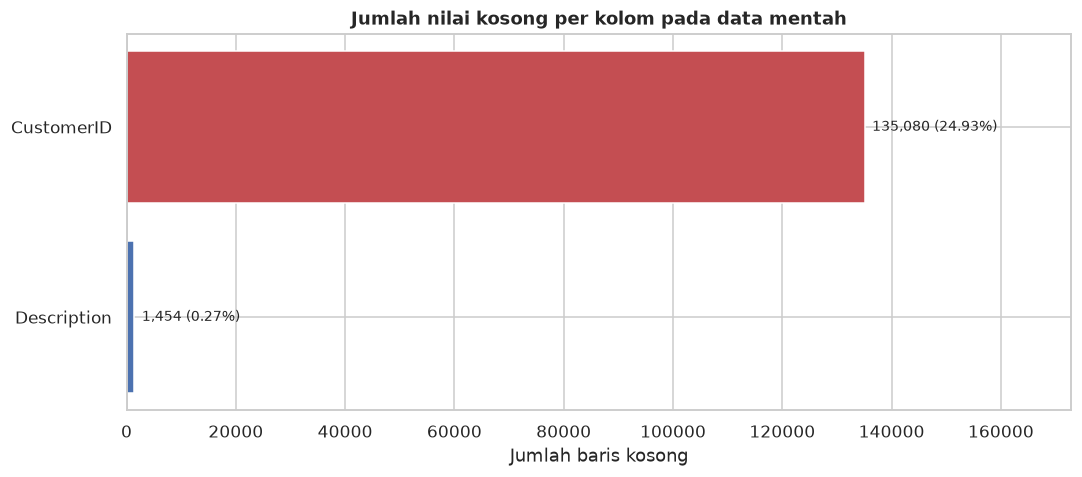

In [6]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#c44e52" if v > 10000 else "#4c72b0" for v in missing.values]
bars = ax.barh(missing.index[::-1], missing.values[::-1], color=colors[::-1], edgecolor="white")
ax.set_title("Jumlah nilai kosong per kolom pada data mentah", fontsize=12, fontweight="bold")
ax.set_xlabel("Jumlah baris kosong")
for bar, value in zip(bars, missing.values[::-1]):
    ax.text(value + max(missing) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{value:,} ({value / len(df_raw) * 100:.2f}%)", va="center", fontsize=9)
ax.set_xlim(0, max(missing) * 1.28)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

# Eksplorasi dan Pembersihan Data

Kolom yang relevan untuk association rule adalah InvoiceNo sebagai identitas transaksi, Description sebagai nama produk, Quantity untuk memastikan baris adalah pembelian, dan StockCode untuk menyaring baris non-produk. InvoiceDate dan UnitPrice dipakai untuk konteks, bukan untuk pembentukan itemset. CustomerID tidak dipakai karena 25% kosong dan tidak diperlukan untuk market basket analysis.

Pembersihan dilakukan bertahap: (1) menyeragamkan Description menjadi huruf kapital dan menghapus spasi berlebih, (2) menghapus Description kosong, (3) menghapus invoice yang dibatalkan dengan InvoiceNo berawalan C, (4) menghapus Quantity negatif atau nol, (5) menghapus baris non-produk seperti postage, manual, carriage, dan gift voucher, serta (6) menghapus duplikat baris. Langkah (5) dan (6) adalah tambahan agar aturan yang dihasilkan benar-benar mencerminkan produk ritel.

In [7]:
df = df_raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()
df["Description"] = df["Description"].astype("string").str.strip().str.upper()

clean_steps = []


def record_step(label, data):
    clean_steps.append({
        "tahap": label,
        "baris": len(data),
        "invoice": data["InvoiceNo"].nunique(),
        "produk": data["Description"].nunique(),
        "description_kosong": int(data["Description"].isna().sum()),
    })


record_step("Data mentah", df)
n_desc_missing = int(df["Description"].isna().sum())
df = df.dropna(subset=["Description"])
record_step("Hapus Description kosong", df)

n_cancel_rows = int(df["InvoiceNo"].str.startswith("C").sum())
n_cancel_invoices = df.loc[df["InvoiceNo"].str.startswith("C"), "InvoiceNo"].nunique()
df = df[~df["InvoiceNo"].str.startswith("C")]
record_step("Hapus invoice batal (C)", df)

n_qty_nonpos = int((df["Quantity"] <= 0).sum())
df = df[df["Quantity"] > 0]
record_step("Hapus Quantity <= 0", df)

NON_PRODUCT_CODES = {
    "POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES",
    "AMAZONFEE", "CRUK", "PADS",
}
stock_code = df["StockCode"]
non_product_mask = stock_code.isin(NON_PRODUCT_CODES) | stock_code.str.startswith("GIFT_")
n_nonproduct = int(non_product_mask.sum())
df = df[~non_product_mask]
record_step("Hapus baris non-produk", df)

n_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates()
record_step("Hapus duplikat", df)

clean_log = pd.DataFrame(clean_steps)
clean_log["baris_terhapus"] = clean_log["baris"].shift(1).fillna(clean_log["baris"]).astype(int) - clean_log["baris"]
clean_log["invoice_terhapus"] = clean_log["invoice"].shift(1).fillna(clean_log["invoice"]).astype(int) - clean_log["invoice"]
display(clean_log)
clean_log.to_csv(cfg.OUTPUT_DIR / "cleaning_summary.csv", index=False)

print(f"Description kosong: {n_desc_missing:,} baris")
print(f"Invoice batal (C): {n_cancel_rows:,} baris dari {n_cancel_invoices:,} invoice")
print(f"Quantity <= 0 setelah invoice batal dihapus: {n_qty_nonpos:,} baris")
print(f"Baris non-produk: {n_nonproduct:,} baris")
print(f"Duplikat: {n_duplicates:,} baris")
print(f"Data final: {len(df):,} baris | {df.InvoiceNo.nunique():,} invoice | {df.Description.nunique():,} produk")

,tahap,baris,invoice,produk,description_kosong,baris_terhapus,invoice_terhapus
0,Data mentah,541909,25900,4194,1454,0,0
1,Hapus Description kosong,540455,24446,4194,0,1454,1454
2,Hapus invoice batal (C),531167,20610,4178,0,9288,3836
3,Hapus Quantity <= 0,530693,20136,4060,0,474,474
4,Hapus baris non-produk,528335,19954,4045,0,2358,182
5,Hapus duplikat,523109,19954,4045,0,5226,0


Description kosong: 1,454 baris
Invoice batal (C): 9,288 baris dari 3,836 invoice
Quantity <= 0 setelah invoice batal dihapus: 474 baris
Baris non-produk: 2,358 baris
Duplikat: 5,226 baris
Data final: 523,109 baris | 19,954 invoice | 4,045 produk


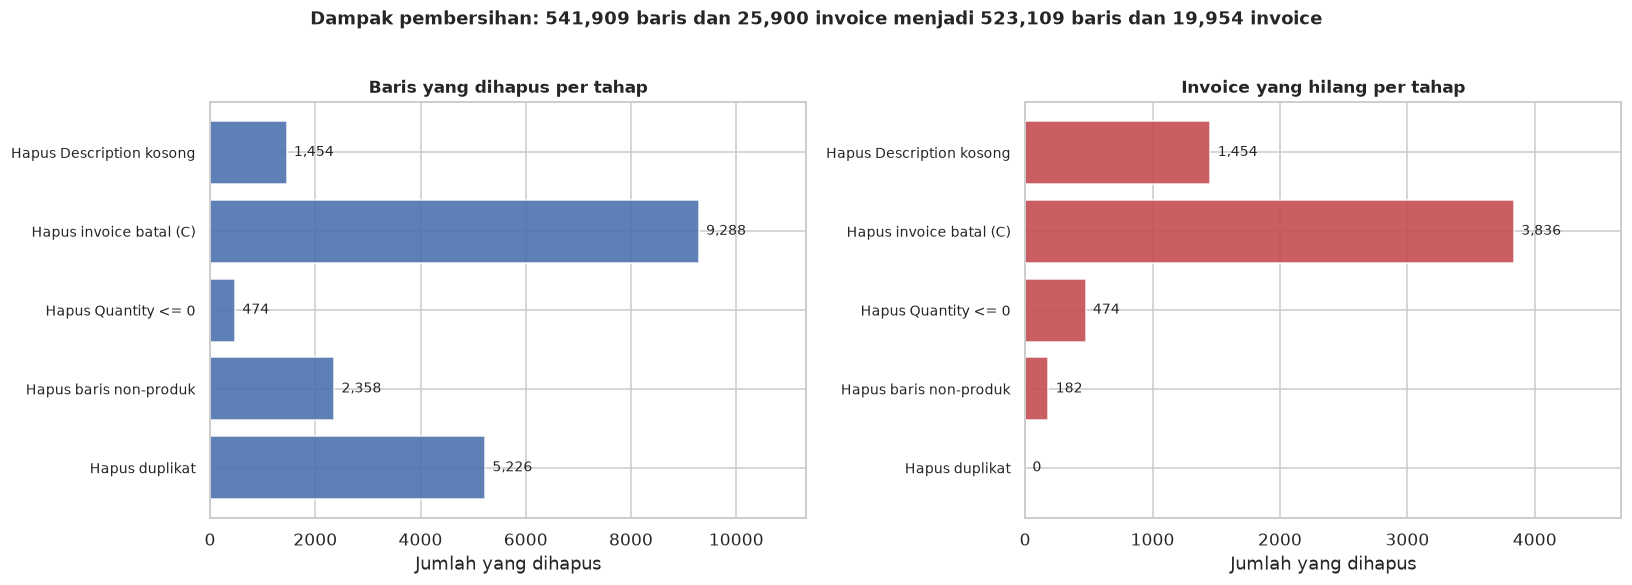

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot_steps = clean_log.iloc[1:].copy()
for ax, col, title, color in [
    (axes[0], "baris_terhapus", "Baris yang dihapus per tahap", "#4c72b0"),
    (axes[1], "invoice_terhapus", "Invoice yang hilang per tahap", "#c44e52"),
]:
    y = np.arange(len(plot_steps))
    bars = ax.barh(y, plot_steps[col].values, color=color, alpha=0.9, edgecolor="white")
    ax.set_yticks(y)
    ax.set_yticklabels(plot_steps["tahap"], fontsize=9)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Jumlah yang dihapus")
    for bar, value in zip(bars, plot_steps[col].values):
        ax.text(value + max(plot_steps[col].max() * 0.015, 1), bar.get_y() + bar.get_height() / 2,
                f"{value:,}", va="center", fontsize=9)
    ax.set_xlim(0, max(plot_steps[col].max() * 1.22, 1))
plt.suptitle(f"Dampak pembersihan: {len(df_raw):,} baris dan {df_raw.InvoiceNo.nunique():,} invoice menjadi {len(df):,} baris dan {df.InvoiceNo.nunique():,} invoice",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "cleaning_funnel.png", dpi=150, bbox_inches="tight")
plt.show()

Pembersihan wajib menghasilkan 530.693 baris dan 20.136 invoice. Setelah filter non-produk dan duplikat, data final berisi 523.109 baris, 19.954 invoice, dan 4.045 produk. Sebanyak 3.836 invoice dibatalkan dan 1.454 invoice hanya berisi baris tanpa Description. Filter non-produk juga menghapus 182 invoice yang seluruh isinya berupa layanan seperti postage atau manual. Duplikat tidak mengubah jumlah invoice karena itemset dibentuk dari himpunan produk unik per invoice.

## Distribusi Ukuran Keranjang dan Produk Terpopuler

Setiap invoice dapat berisi banyak produk. Ukuran keranjang dihitung dari jumlah Description unik per invoice. Distribusinya miring ke kanan: median 15 produk, rata-rata 25,94 produk, dan nilai maksimum 1.106 produk. Sebanyak 1.662 invoice (8,33%) hanya berisi satu produk sehingga tidak dapat membentuk aturan asosiasi, tetapi tetap dihitung dalam denominator support.

,count,mean,std,min,25%,50%,75%,max
unique_items,19954.0,25.94,46.82,1.0,6.0,15.0,29.0,1106.0


,unique_items
0.50,15.00
0.75,29.00
0.90,52.00
0.95,75.00
0.99,216.47


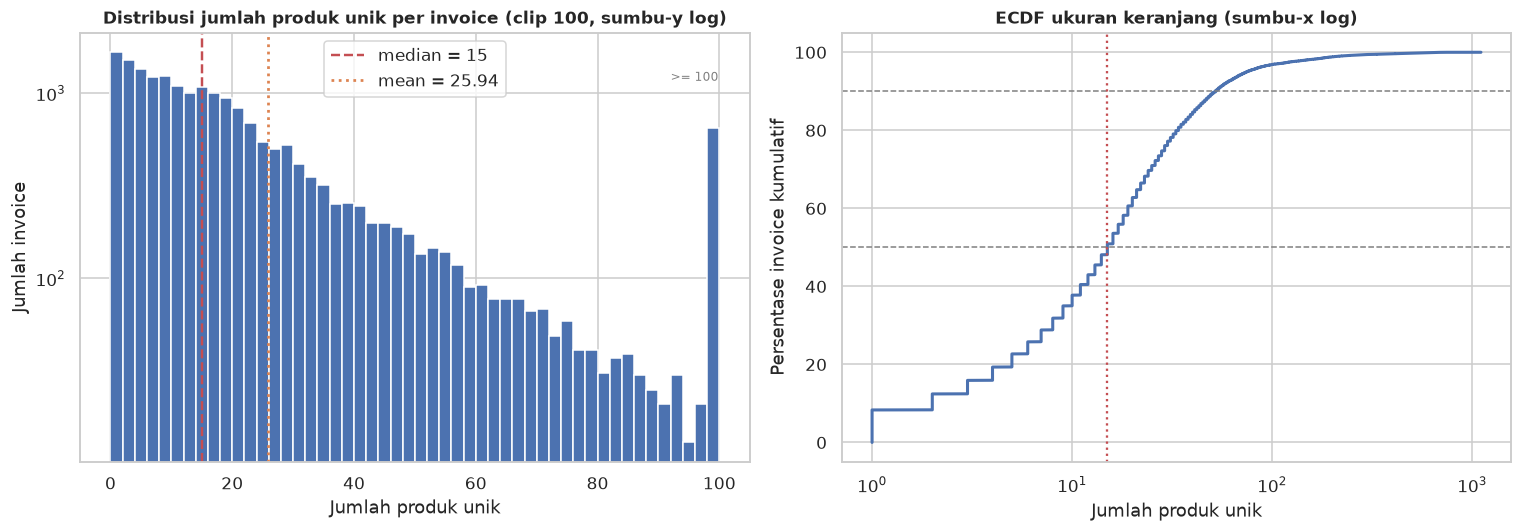

In [9]:
invoice_sizes = df.groupby("InvoiceNo")["Description"].nunique()
display(invoice_sizes.describe().to_frame("unique_items").T.round(2))
display(invoice_sizes.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("unique_items").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(invoice_sizes.clip(upper=100), bins=range(0, 102, 2), color="#4c72b0", edgecolor="white")
axes[0].set_yscale("log")
axes[0].axvline(invoice_sizes.median(), color="#c44e52", linestyle="--", linewidth=1.6, label=f"median = {invoice_sizes.median():.0f}")
axes[0].axvline(invoice_sizes.mean(), color="#dd8452", linestyle=":", linewidth=1.8, label=f"mean = {invoice_sizes.mean():.2f}")
axes[0].set_title("Distribusi jumlah produk unik per invoice (clip 100, sumbu-y log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Jumlah produk unik")
axes[0].set_ylabel("Jumlah invoice")
axes[0].legend()
axes[0].text(92, axes[0].get_ylim()[1] * 0.55, ">= 100", fontsize=8, color="gray")

sorted_sizes = np.sort(invoice_sizes.values)
ecdf = np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes) * 100
axes[1].plot(sorted_sizes, ecdf, color="#4c72b0", linewidth=2)
axes[1].set_xscale("log")
axes[1].axhline(50, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(15, color="#c44e52", linestyle=":", linewidth=1.5)
axes[1].set_title("ECDF ukuran keranjang (sumbu-x log)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Jumlah produk unik")
axes[1].set_ylabel("Persentase invoice kumulatif")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "invoice_size_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

,jumlah_invoice,support_pct
Description,,
WHITE HANGING HEART T-LIGHT HOLDER,2260,11.33
JUMBO BAG RED RETROSPOT,2092,10.48
REGENCY CAKESTAND 3 TIER,1989,9.97
PARTY BUNTING,1686,8.45
LUNCH BAG RED RETROSPOT,1564,7.84
ASSORTED COLOUR BIRD ORNAMENT,1455,7.29
SET OF 3 CAKE TINS PANTRY DESIGN,1385,6.94
PACK OF 72 RETROSPOT CAKE CASES,1320,6.62
LUNCH BAG BLACK SKULL.,1273,6.38


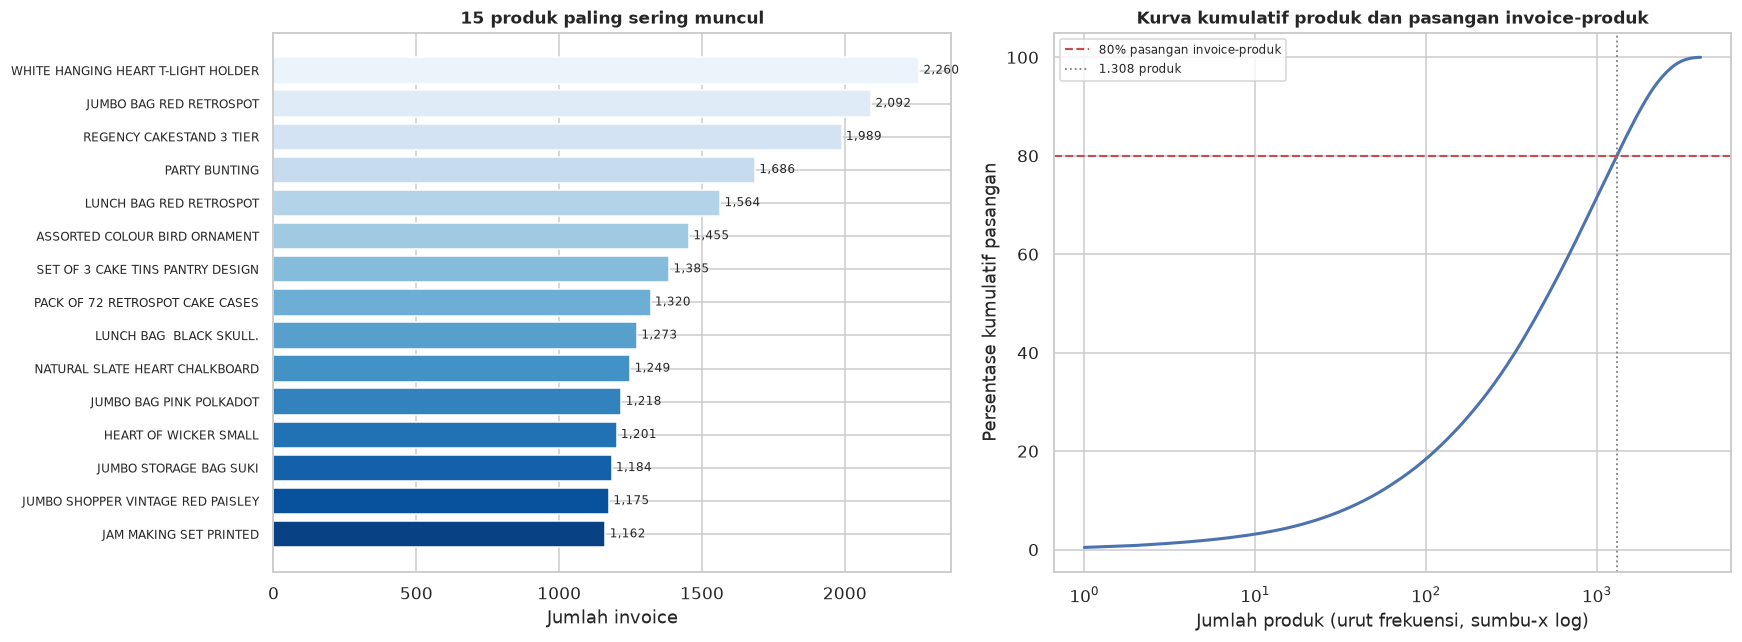

Top 10 produk mencakup 3.14% pasangan invoice-produk
Produk yang dibutuhkan untuk 80% pasangan: 1,308


In [10]:
product_freq = df.groupby("Description")["InvoiceNo"].nunique().sort_values(ascending=False)
product_support = product_freq / df.InvoiceNo.nunique() * 100
top_products = pd.DataFrame({
    "jumlah_invoice": product_freq.head(15),
    "support_pct": product_support.head(15).round(2),
})
display(top_products)
top_products.to_csv(cfg.OUTPUT_DIR / "top_products.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top15 = product_freq.head(15).sort_values()
colors = sns.color_palette("Blues_r", len(top15))
axes[0].barh(top15.index, top15.values, color=colors, edgecolor="white")
axes[0].set_title("15 produk paling sering muncul", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Jumlah invoice")
axes[0].tick_params(axis="y", labelsize=8)
for i, value in enumerate(top15.values):
    axes[0].text(value + 15, i, f"{value:,}", va="center", fontsize=8)

cum_share = product_freq.cumsum() / product_freq.sum() * 100
axes[1].plot(np.arange(1, len(product_freq) + 1), cum_share.values, color="#4c72b0", linewidth=2)
axes[1].set_xscale("log")
axes[1].axhline(80, color="#c44e52", linestyle="--", linewidth=1.4, label="80% pasangan invoice-produk")
axes[1].axvline(1308, color="gray", linestyle=":", linewidth=1.2, label="1.308 produk")
axes[1].set_title("Kurva kumulatif produk dan pasangan invoice-produk", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Jumlah produk (urut frekuensi, sumbu-x log)")
axes[1].set_ylabel("Persentase kumulatif pasangan")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "top_products.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top 10 produk mencakup {cum_share.iloc[9]:.2f}% pasangan invoice-produk")
print(f"Produk yang dibutuhkan untuk 80% pasangan: {int((cum_share < 80).sum() + 1):,}")

Produk terpopuler adalah WHITE HANGING HEART T-LIGHT HOLDER (2.260 invoice, 11,33%), JUMBO BAG RED RETROSPOT (2.092 invoice, 10,48%), dan REGENCY CAKESTAND 3 TIER (1.989 invoice, 9,97%). Sepuluh produk teratas hanya mencakup 3,14% dari seluruh pasangan invoice-produk, dan dibutuhkan 1.308 produk untuk mencakup 80% pasangan. Ini menunjukkan distribusi long tail yang kuat, sehingga support minimum 1% sampai 2% sudah cukup selektif.

# Persiapan Data untuk Association Rule

Data baris demi baris diubah menjadi transaksi berbasis invoice. Untuk setiap InvoiceNo, daftar Description diubah menjadi himpunan (set) agar produk yang sama tidak dihitung dua kali dalam satu invoice. Hasilnya adalah 19.954 transaksi dengan rata-rata 25,94 produk unik per transaksi. Selanjutnya transaksi diubah menjadi matriks one-hot berukuran 19.954 x 4.045; nilai 1 berarti produk dibeli pada invoice tersebut dan 0 berarti tidak. Kepadatan matriks hanya 0,64%, jadi matriks bersifat sangat sparse.

In [11]:
transactions = df.groupby("InvoiceNo")["Description"].apply(lambda items: sorted(set(items)))
transaction_sizes = transactions.apply(len)


def short_list(items, max_len=110):
    text = ", ".join(items)
    return text if len(text) <= max_len else text[: max_len - 3] + "..."


preview = pd.DataFrame({
    "invoice": transactions.index[:5],
    "n_produk": transaction_sizes.head(5).values,
    "produk": [short_list(items) for items in transactions.head(5)],
}).set_index("invoice")
display(preview)
print(f"Jumlah transaksi: {len(transactions):,}")
print(f"Rata-rata produk unik per transaksi: {transaction_sizes.mean():.2f}")
print(f"Median produk unik per transaksi: {transaction_sizes.median():.0f}")
print(f"Ukuran transaksi terbesar: {transaction_sizes.max():,}")

,n_produk,produk
invoice,,
536365,7,"CREAM CUPID HEARTS COAT HANGER, GLASS STAR FROSTED T-LIGHT HOLDER, KNITTED UNION FLAG HOT WATER BOTTLE, RED..."
536366,2,"HAND WARMER RED POLKA DOT, HAND WARMER UNION JACK"
536367,12,"ASSORTED COLOUR BIRD ORNAMENT, BOX OF 6 ASSORTED COLOUR TEASPOONS, BOX OF VINTAGE ALPHABET BLOCKS, BOX OF V..."
536368,4,"BLUE COAT RACK PARIS FASHION, JAM MAKING SET WITH JARS, RED COAT RACK PARIS FASHION, YELLOW COAT RACK PARIS..."
536369,1,BATH BUILDING BLOCK WORD


Jumlah transaksi: 19,954
Rata-rata produk unik per transaksi: 25.94
Median produk unik per transaksi: 15
Ukuran transaksi terbesar: 1,106


In [12]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_array, columns=te.columns_, index=transactions.index)

print(f"Shape basket: {basket.shape}")
print(f"Kepadatan matriks: {basket.values.mean() * 100:.4f}%")
print(f"Memori matriks: {basket.values.nbytes / 1e6:.1f} MB")

top_cols = product_freq.head(8).index.tolist()
display(basket.loc[transactions.index[:5], top_cols].astype(int))

Shape basket: (19954, 4045)
Kepadatan matriks: 0.6412%
Memori matriks: 80.7 MB


,WHITE HANGING HEART T-LIGHT HOLDER,JUMBO BAG RED RETROSPOT,REGENCY CAKESTAND 3 TIER,PARTY BUNTING,LUNCH BAG RED RETROSPOT,ASSORTED COLOUR BIRD ORNAMENT,SET OF 3 CAKE TINS PANTRY DESIGN,PACK OF 72 RETROSPOT CAKE CASES
InvoiceNo,,,,,,,,
536365,1,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,1,0,0
536368,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0


# Penerapan Algoritma Association Rule

Algoritma yang dipakai adalah FP-Growth. FP-Growth membangun FP-tree untuk memadatkan transaksi sehingga tidak perlu membangkitkan kandidat secara eksplisit seperti Apriori. Pada dataset ini terdapat 4.045 produk; Apriori dengan support 1% mengalami ledakan kandidat dan tidak praktis dijalankan, sedangkan FP-Growth menyelesaikan pencarian dalam hitungan detik. Sebagai validasi, Apriori pada support 2% menghasilkan jumlah itemset dan aturan yang sama dengan FP-Growth.

Parameter awal mengikuti tugas: minimum support 0,01 dan minimum confidence 0,5. Kombinasi ini menghasilkan 1.820 frequent itemset dan 816 aturan. Jumlah 816 aturan terlalu banyak untuk ditinjau dan banyak aturan yang merupakan cermin dari aturan lain, misalnya A -> B dan B -> A, atau permutasi dari itemset yang sama.

In [13]:
def itemset_text(itemset):
    return ", ".join(sorted(itemset))


def add_rule_text(frame):
    out = frame.copy()
    out["rule"] = out.apply(
        lambda row: f"{itemset_text(row['antecedents'])} -> {itemset_text(row['consequents'])}",
        axis=1,
    )
    return out


t0 = time.time()
freq_itemsets_001 = fpgrowth(basket, min_support=0.01, use_colnames=True)
t_fp_001 = time.time() - t0
rules_001 = association_rules(freq_itemsets_001, metric="confidence", min_threshold=0.5)
rules_001 = add_rule_text(rules_001).sort_values(["lift", "confidence"], ascending=False)

print(f"Frequent itemset (support 0,01): {len(freq_itemsets_001):,}")
print(f"Aturan (support 0,01; confidence 0,5): {len(rules_001):,}")
print(f"Waktu FP-Growth: {t_fp_001:.2f} detik")
display(rules_001[["rule", "support", "confidence", "lift"]].head(10).round(4))

Frequent itemset (support 0,01): 1,820
Aturan (support 0,01; confidence 0,5): 816
Waktu FP-Growth: 2.89 detik


,rule,support,confidence,lift
378,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY -> HERB MARKER THYME",0.0102,0.9442,79.4949
379,"HERB MARKER THYME -> HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.0102,0.8565,79.4949
376,"HERB MARKER PARSLEY, HERB MARKER THYME -> HERB MARKER ROSEMARY",0.0102,0.9531,79.2383
381,"HERB MARKER ROSEMARY -> HERB MARKER PARSLEY, HERB MARKER THYME",0.0102,0.8458,79.2383
382,"HERB MARKER BASIL, HERB MARKER THYME -> HERB MARKER ROSEMARY",0.0100,0.9524,79.1825
387,"HERB MARKER ROSEMARY -> HERB MARKER BASIL, HERB MARKER THYME",0.0100,0.8333,79.1825
383,"HERB MARKER BASIL, HERB MARKER ROSEMARY -> HERB MARKER THYME",0.0100,0.9346,78.6861
386,"HERB MARKER THYME -> HERB MARKER BASIL, HERB MARKER ROSEMARY",0.0100,0.8439,78.6861
368,HERB MARKER THYME -> HERB MARKER ROSEMARY,0.0111,0.9325,77.5287
369,HERB MARKER ROSEMARY -> HERB MARKER THYME,0.0111,0.9208,77.5287


Karena 816 aturan terlalu banyak, parameter dinaikkan secara bertahap. Tabel dan grafik berikut menunjukkan trade-off antara minimum support, minimum confidence, jumlah frequent itemset, dan jumlah aturan. Pada support 0,015 dan confidence 0,6 masih ada 97 aturan; pada support 0,02 dan confidence 0,6 tersisa 30 aturan; pada support 0,03 hanya tersisa 9 aturan. Support 0,02 dipilih karena masih mencakup minimal 399 invoice (2% dari 19.954) dan confidence 0,6 menjaga aturan tetap cukup kuat tanpa memangkas terlalu banyak pola.

min_confidence,0.5,0.6,0.7
min_support,,,
0.0100,1820,1820,1820
0.0125,1072,1072,1072
0.0150,701,701,701
0.0175,507,507,507
0.0200,376,376,376
0.0250,223,223,223
0.0300,140,140,140
0.0400,66,66,66
0.0500,32,32,32


min_confidence,0.5,0.6,0.7
min_support,,,
0.0100,816,484,261
0.0125,374,202,94
0.0150,182,97,45
0.0175,88,39,19
0.0200,60,30,13
0.0250,37,21,10
0.0300,13,9,4
0.0400,1,1,0
0.0500,0,0,0


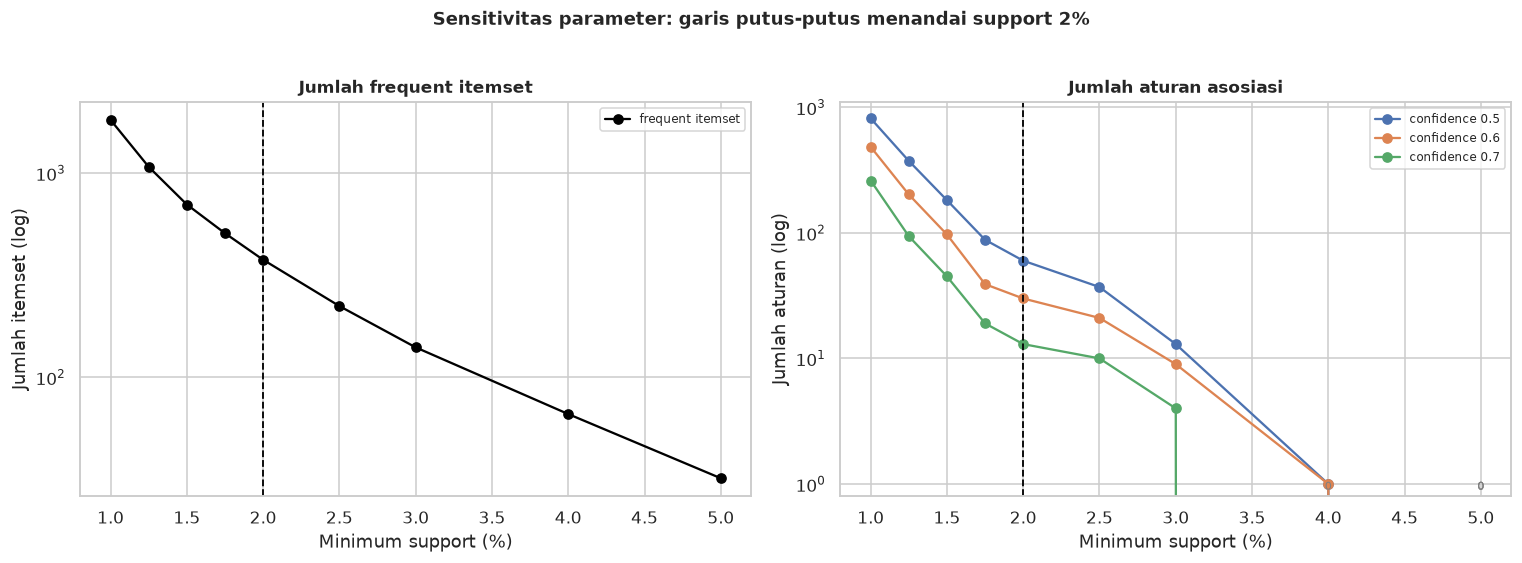

In [14]:
supports = [0.010, 0.0125, 0.015, 0.0175, 0.020, 0.025, 0.030, 0.040, 0.050]
confidences = [0.5, 0.6, 0.7]
sensitivity_rows = []

for min_sup in supports:
    freq = fpgrowth(basket, min_support=min_sup, use_colnames=True)
    for min_conf in confidences:
        rules_tmp = association_rules(freq, metric="confidence", min_threshold=min_conf)
        sensitivity_rows.append({
            "min_support": min_sup,
            "min_confidence": min_conf,
            "frequent_itemsets": len(freq),
            "rules": len(rules_tmp),
        })

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.pivot(index="min_support", columns="min_confidence", values="frequent_itemsets"))
display(sensitivity.pivot(index="min_support", columns="min_confidence", values="rules"))
sensitivity.to_csv(cfg.OUTPUT_DIR / "parameter_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
itemset_curve = sensitivity[sensitivity["min_confidence"] == 0.5]
axes[0].plot(itemset_curve["min_support"] * 100, itemset_curve["frequent_itemsets"],
             marker="o", color="black", label="frequent itemset")
for min_conf in confidences:
    subset = sensitivity[sensitivity["min_confidence"] == min_conf]
    axes[1].plot(subset["min_support"] * 100, subset["rules"], marker="o", label=f"confidence {min_conf}")
for ax, title in [(axes[0], "Jumlah frequent itemset"), (axes[1], "Jumlah aturan asosiasi")]:
    ax.set_yscale("log")
    ax.axvline(2.0, color="black", linestyle="--", linewidth=1.2)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Minimum support (%)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Jumlah itemset (log)")
axes[1].set_ylabel("Jumlah aturan (log)")
axes[1].set_ylim(0.8, sensitivity["rules"].max() * 1.35)
for _, row in sensitivity[sensitivity["rules"] == 0].iterrows():
    axes[1].annotate("0", (row["min_support"] * 100, 0.9), ha="center", fontsize=7, color="gray")
plt.suptitle("Sensitivitas parameter: garis putus-putus menandai support 2%", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "parameter_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Final: Support 0,02 dan Confidence 0,6

Kombinasi final minimum support 0,02 dan minimum confidence 0,6 menghasilkan 376 frequent itemset dan 30 aturan. Dari 376 itemset, 295 berupa satu produk, 78 berupa pasangan produk, dan 3 berupa triplet produk. Tidak ada itemset dengan empat produk atau lebih pada threshold ini. FP-Growth menyelesaikan pencarian itemset dalam sekitar 1,5 detik, sedangkan Apriori pada threshold yang sama membutuhkan sekitar 3 detik dan menghasilkan 30 aturan yang identik.

In [15]:
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.6

t0 = time.time()
frequent_itemsets = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True)
t_fp = time.time() - t0

t0 = time.time()
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
t_rules = time.time() - t0
rules = add_rule_text(rules).sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
rules["support_pct"] = (rules["support"] * 100).round(4)

display(rules[["rule", "support", "support_pct", "confidence", "lift", "leverage", "conviction"]].round(4))
print(f"Frequent itemset: {len(frequent_itemsets):,}")
print(f"Aturan asosiasi: {len(rules):,}")
print(f"Waktu FP-Growth: {t_fp:.2f} detik | waktu association_rules: {t_rules:.2f} detik")
rules.to_csv(cfg.OUTPUT_DIR / "rules_final.csv", index=False)

frequent_out = frequent_itemsets.copy()
frequent_out["itemset"] = frequent_out["itemsets"].apply(itemset_text)
frequent_out["panjang"] = frequent_out["itemsets"].apply(len)
frequent_out = frequent_out.sort_values("support", ascending=False)
frequent_out[["itemset", "support", "panjang"]].to_csv(cfg.OUTPUT_DIR / "frequent_itemsets.csv", index=False)

,rule,support,support_pct,confidence,lift,leverage,conviction
0,"PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0272,2.7162,0.7076,18.3840,0.0257,3.2880
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER",0.0272,2.7162,0.7057,18.3840,0.0257,3.2678
2,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER",0.0272,2.7162,0.9048,17.7884,0.0256,9.9742
3,PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER,0.0317,3.1723,0.8264,16.2457,0.0298,5.4664
4,GREEN REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER,0.0317,3.1723,0.6236,16.2457,0.0298,2.5551
5,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER",0.0272,2.7162,0.8562,16.0276,0.0255,6.5844
6,GARDENERS KNEELING PAD CUP OF TEA -> GARDENERS KNEELING PAD KEEP CALM,0.0274,2.7363,0.7203,15.7428,0.0256,3.4119
7,"REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER",0.0204,2.0447,0.7771,15.2779,0.0191,4.2589
8,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEACUP AND SAUCER",0.0204,2.0447,0.8016,15.0043,0.0191,4.7704
9,PINK REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER,0.0300,3.0019,0.7820,14.6376,0.0280,4.3418


Frequent itemset: 376
Aturan asosiasi: 30
Waktu FP-Growth: 1.50 detik | waktu association_rules: 0.00 detik


In [16]:
t0 = time.time()
freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
t_apriori = time.time() - t0
rules_apriori = association_rules(freq_apriori, metric="confidence", min_threshold=MIN_CONFIDENCE)
print(f"FP-Growth: {len(frequent_itemsets):,} itemset, {len(rules):,} aturan, {t_fp:.2f} detik")
print(f"Apriori:   {len(freq_apriori):,} itemset, {len(rules_apriori):,} aturan, {t_apriori:.2f} detik")

FP-Growth: 376 itemset, 30 aturan, 1.50 detik
Apriori:   376 itemset, 30 aturan, 1.69 detik


,jumlah_itemset
itemsets,
1,295
2,78
3,3


,itemset,support,panjang
303,"JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROSPOT",0.0413,2
344,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0385,2
305,"JUMBO BAG RED RETROSPOT, JUMBO STORAGE BAG SUKI",0.0363,2
318,"JUMBO BAG RED RETROSPOT, JUMBO SHOPPER VINTAGE RED PAISLEY",0.0341,2
336,"LUNCH BAG BLACK SKULL., LUNCH BAG RED RETROSPOT",0.0321,2
296,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED",0.0321,2
357,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER",0.0317,2
328,"LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT",0.0304,2
358,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0300,2
309,"JUMBO BAG BAROQUE BLACK WHITE, JUMBO BAG RED RETROSPOT",0.0293,2


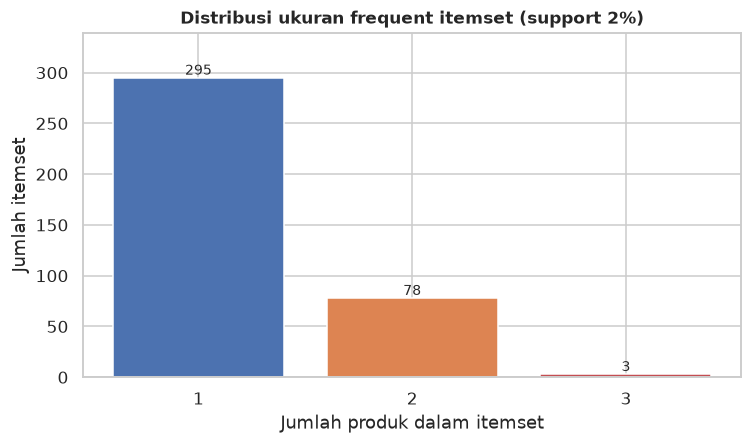

In [17]:
itemset_sizes = frequent_itemsets["itemsets"].apply(len).value_counts().sort_index()
display(itemset_sizes.to_frame("jumlah_itemset"))
multi_itemsets = frequent_out[frequent_out["panjang"] > 1].head(12)
display(multi_itemsets[["itemset", "support", "panjang"]].round(4))

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = ["#4c72b0", "#dd8452", "#c44e52"][: len(itemset_sizes)]
bars = ax.bar(itemset_sizes.index.astype(str), itemset_sizes.values, color=colors, edgecolor="white")
ax.set_title("Distribusi ukuran frequent itemset (support 2%)", fontsize=11, fontweight="bold")
ax.set_xlabel("Jumlah produk dalam itemset")
ax.set_ylabel("Jumlah itemset")
for bar, value in zip(bars, itemset_sizes.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{value:,}", ha="center", fontsize=9)
ax.set_ylim(0, max(itemset_sizes.values) * 1.15)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "itemset_size.png", dpi=150, bbox_inches="tight")
plt.show()

# Evaluasi Aturan Asosiasi

Support mengukur proporsi invoice yang mengandung antecedent dan consequent sekaligus. Confidence mengukur proporsi invoice dengan antecedent yang juga mengandung consequent. Lift mengukur seberapa lebih sering consequent muncul ketika antecedent ada dibandingkan kemunculannya secara umum. Lift 1 berarti independen, lift > 1 berarti asosiasi positif, dan lift < 1 berarti asosiasi negatif. Leverage mengukur selisih support gabungan dari perkalian support marginal; conviction mengukur kekuatan implikasi. Aturan diurutkan berdasarkan lift, lalu confidence.

In [18]:
top_rules = rules.head(10).copy()
display(top_rules[["rule", "support_pct", "confidence", "lift", "leverage"]].round(4))
top_rules.to_csv(cfg.OUTPUT_DIR / "top_rules.csv", index=False)

,rule,support_pct,confidence,lift,leverage
0,"PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",2.7162,0.7076,18.3840,0.0257
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER",2.7162,0.7057,18.3840,0.0257
2,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER",2.7162,0.9048,17.7884,0.0256
3,PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER,3.1723,0.8264,16.2457,0.0298
4,GREEN REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER,3.1723,0.6236,16.2457,0.0298
5,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER",2.7162,0.8562,16.0276,0.0255
6,GARDENERS KNEELING PAD CUP OF TEA -> GARDENERS KNEELING PAD KEEP CALM,2.7363,0.7203,15.7428,0.0256
7,"REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER",2.0447,0.7771,15.2779,0.0191
8,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEACUP AND SAUCER",2.0447,0.8016,15.0043,0.0191
9,PINK REGENCY TEACUP AND SAUCER -> ROSES REGENCY TEACUP AND SAUCER,3.0019,0.7820,14.6376,0.0280


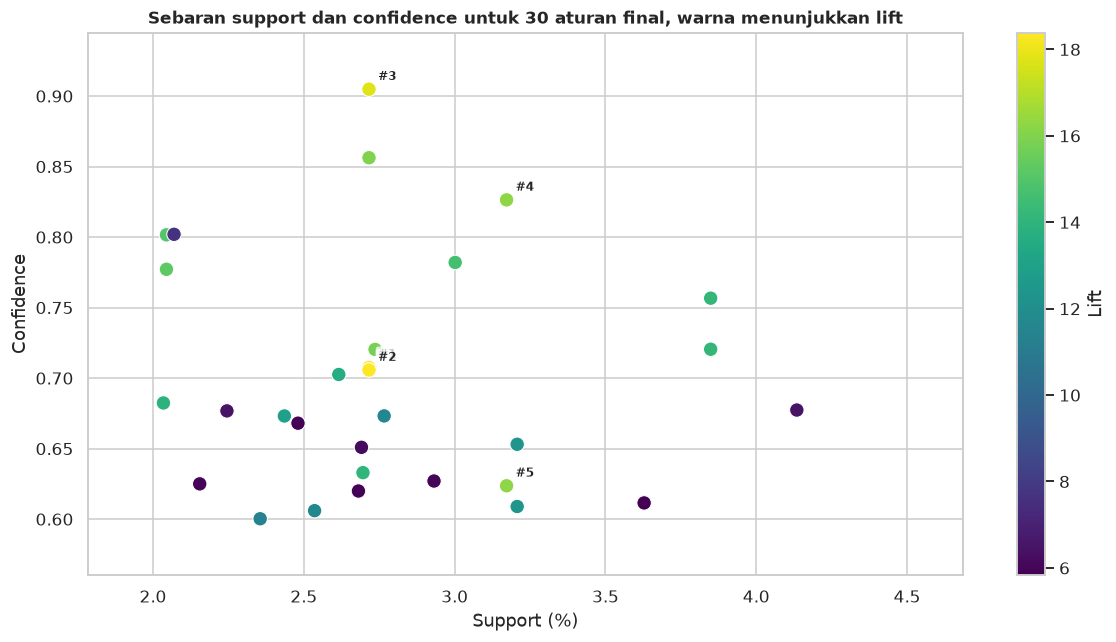

In [19]:
def short_label(text, max_len=42):
    return text if len(text) <= max_len else text[: max_len - 3] + "..."


plot_df = rules.copy()
fig, ax = plt.subplots(figsize=(11, 6))
scatter = ax.scatter(
    plot_df["support_pct"], plot_df["confidence"],
    c=plot_df["lift"], cmap="viridis", s=90, edgecolor="white", linewidth=0.7,
)
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Lift")
for rank, (_, row) in enumerate(plot_df.head(5).iterrows(), start=1):
    ax.annotate(
        f"#{rank}",
        (row["support_pct"], row["confidence"]),
        xytext=(6, 6), textcoords="offset points", fontsize=8, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75, edgecolor="none"),
    )
ax.set_title("Sebaran support dan confidence untuk 30 aturan final, warna menunjukkan lift", fontsize=11, fontweight="bold")
ax.set_xlabel("Support (%)")
ax.set_ylabel("Confidence")
ax.set_xlim(plot_df["support_pct"].min() - 0.25, plot_df["support_pct"].max() + 0.55)
ax.set_ylim(plot_df["confidence"].min() - 0.04, plot_df["confidence"].max() + 0.04)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "support_confidence_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

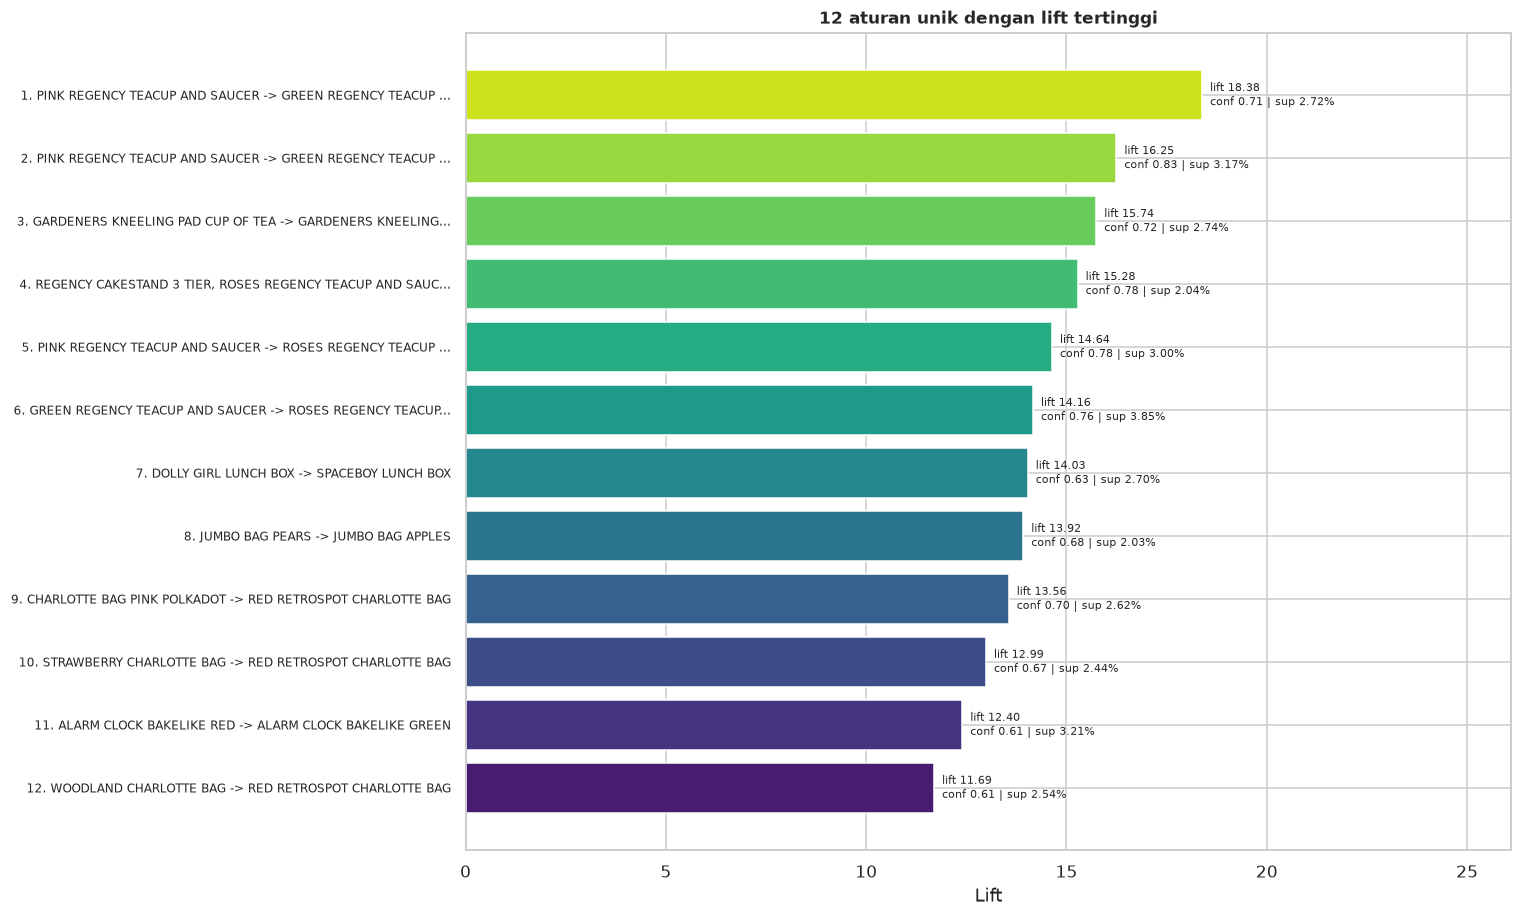

In [20]:
rules["combined_key"] = rules.apply(lambda row: frozenset(row["antecedents"] | row["consequents"]), axis=1)
rules_unique = rules.drop_duplicates("combined_key").head(12).copy()
rules_unique["label"] = [
    f"{rank}. {short_label(rule, 58)}"
    for rank, rule in enumerate(rules_unique["rule"], start=1)
]

fig, ax = plt.subplots(figsize=(14, 8.5))
plot_unique = rules_unique.iloc[::-1]
bars = ax.barh(plot_unique["label"], plot_unique["lift"], color=sns.color_palette("viridis", len(plot_unique)), edgecolor="white")
ax.set_title("12 aturan unik dengan lift tertinggi", fontsize=11, fontweight="bold")
ax.set_xlabel("Lift")
ax.tick_params(axis="y", labelsize=8)
for bar, lift, confidence, support in zip(bars, plot_unique["lift"], plot_unique["confidence"], plot_unique["support_pct"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"lift {lift:.2f}\nconf {confidence:.2f} | sup {support:.2f}%", va="center", fontsize=7.5)
ax.set_xlim(0, plot_unique["lift"].max() * 1.42)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "top_rules_lift.png", dpi=150, bbox_inches="tight")
plt.show()

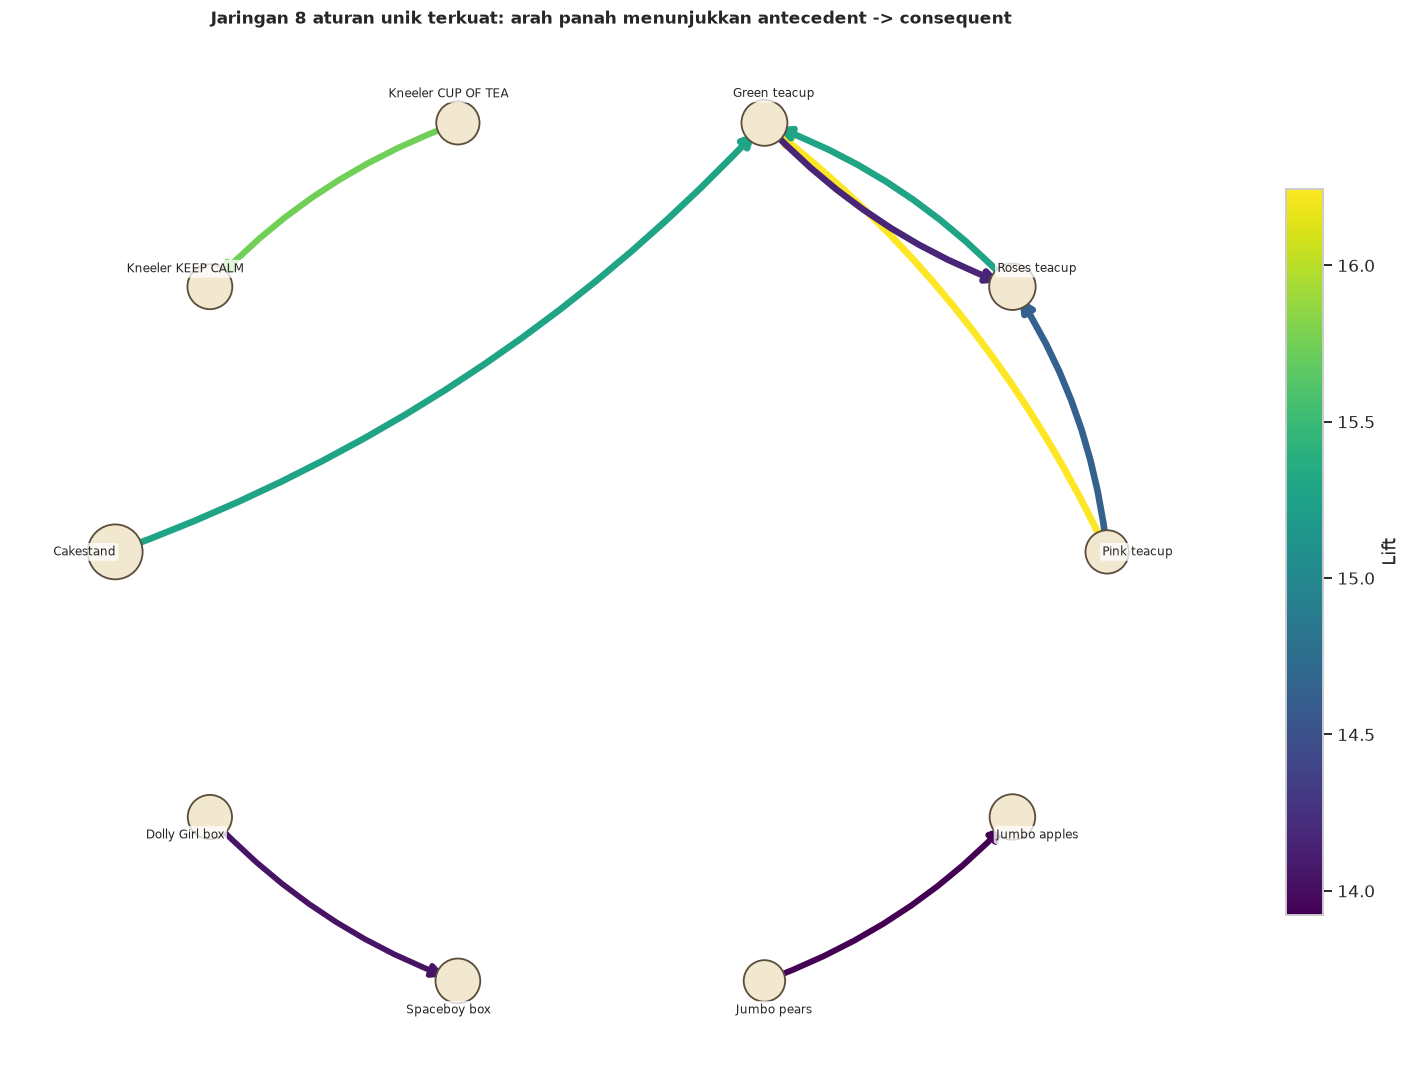

In [21]:
graph = nx.DiGraph()
top_network = rules_unique.head(8)
for _, row in top_network.iterrows():
    for antecedent in row["antecedents"]:
        for consequent in row["consequents"]:
            graph.add_edge(antecedent, consequent, confidence=row["confidence"], lift=row["lift"])

NODE_LABELS = {
    "GARDENERS KNEELING PAD CUP OF TEA": "Kneeler CUP OF TEA",
    "GARDENERS KNEELING PAD KEEP CALM": "Kneeler KEEP CALM",
    "GREEN REGENCY TEACUP AND SAUCER": "Green teacup",
    "ROSES REGENCY TEACUP AND SAUCER": "Roses teacup",
    "PINK REGENCY TEACUP AND SAUCER": "Pink teacup",
    "REGENCY CAKESTAND 3 TIER": "Cakestand",
    "DOLLY GIRL LUNCH BOX": "Dolly Girl box",
    "SPACEBOY LUNCH BOX": "Spaceboy box",
    "JUMBO BAG PEARS": "Jumbo pears",
    "JUMBO BAG APPLES": "Jumbo apples",
    "CHARLOTTE BAG PINK POLKADOT": "Charlotte pink",
    "RED RETROSPOT CHARLOTTE BAG": "Charlotte red",
    "STRAWBERRY CHARLOTTE BAG": "Charlotte strawberry",
    "ALARM CLOCK BAKELIKE RED": "Clock red",
    "ALARM CLOCK BAKELIKE GREEN": "Clock green",
}

pos = nx.circular_layout(graph)
node_sizes = [500 + product_freq.get(node, 0) / product_freq.max() * 900 for node in graph.nodes()]
edge_widths = [1.2 + graph[u][v]["confidence"] * 4 for u, v in graph.edges()]
edge_lifts = [graph[u][v]["lift"] for u, v in graph.edges()]

fig, ax = plt.subplots(figsize=(14, 10))
nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=node_sizes, node_color="#f2e8cf", edgecolors="#5c4d3c", linewidths=1.2)
edges = nx.draw_networkx_edges(
    graph, pos, ax=ax, width=edge_widths, edge_color=edge_lifts,
    edge_cmap=plt.cm.viridis, edge_vmin=min(edge_lifts), edge_vmax=max(edge_lifts),
    arrows=True, arrowstyle="-|>", arrowsize=16, connectionstyle="arc3,rad=0.12",
)
for node, (x, y) in pos.items():
    norm = np.hypot(x, y)
    offset = (x / norm * 20, y / norm * 20) if norm > 0 else (0, 20)
    label = NODE_LABELS.get(node, short_label(node, 24))
    ax.annotate(
        label, (x, y), xytext=offset, textcoords="offset points",
        ha="center", va="center", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.78, edgecolor="none"),
    )
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(edge_lifts), vmax=max(edge_lifts)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.7)
cbar.set_label("Lift")
ax.set_title("Jaringan 8 aturan unik terkuat: arah panah menunjukkan antecedent -> consequent", fontsize=11, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "rule_network.png", dpi=150, bbox_inches="tight")
plt.show()

Tiga aturan teratas berdasarkan lift seluruhnya berasal dari itemset tiga cangkir Regency. Aturan-aturan ini saling mencerminkan sehingga dibaca sebagai satu pola: pelanggan yang membeli satu varian cangkir Regency cenderung melengkapi koleksinya dengan varian lain. Setelah pola cangkir Regency, pola berbeda dengan lift tertinggi adalah garden kneeler, lunch box, dan jumbo bag.

## Tiga Aturan Terbaik

Jika diurutkan murni berdasarkan lift, tiga aturan teratas adalah:

1. PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER (lift 18,38; confidence 0,708; support 2,72%).
2. GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER (lift 18,38; confidence 0,706; support 2,72%).
3. PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER (lift 17,79; confidence 0,905; support 2,72%).

Ketiganya berasal dari itemset yang sama. Interpretasi bisnisnya: ketiga warna cangkir Regency dibeli sebagai satu set koleksi. Aturan ketiga paling kuat dari sisi confidence: jika pelanggan sudah membeli pink dan roses, 90,5% di antaranya juga membeli green. Untuk rekomendasi praktis, tiga pola berbeda dengan lift tertinggi adalah garden kneeler, lunch box, dan jumbo bag.

In [22]:
top3 = rules.head(3)[["rule", "support_pct", "confidence", "lift"]].copy()
display(top3.round(4))

pattern_specs = [
    ("Regency teacup set", "PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES"),
    ("Garden kneeler", "GARDENERS KNEELING PAD CUP OF TEA"),
    ("Lunch box anak", "DOLLY GIRL LUNCH BOX"),
    ("Jumbo bag", "JUMBO BAG PEARS"),
]
pattern_rows = []
for label, needle in pattern_specs:
    match = rules[rules["rule"].str.startswith(needle)]
    if not match.empty:
        row = match.iloc[0]
        pattern_rows.append({
            "pola": label,
            "rule": row["rule"],
            "support_pct": row["support_pct"],
            "confidence": row["confidence"],
            "lift": row["lift"],
        })
display(pd.DataFrame(pattern_rows).round(4))

,rule,support_pct,confidence,lift
0,"PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",2.7162,0.7076,18.3840
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> PINK REGENCY TEACUP AND SAUCER",2.7162,0.7057,18.3840
2,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER",2.7162,0.9048,17.7884


,pola,rule,support_pct,confidence,lift
0,Regency teacup set,"PINK REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",2.7162,0.7076,18.3840
1,Garden kneeler,GARDENERS KNEELING PAD CUP OF TEA -> GARDENERS KNEELING PAD KEEP CALM,2.7363,0.7203,15.7428
2,Lunch box anak,DOLLY GIRL LUNCH BOX -> SPACEBOY LUNCH BOX,2.6962,0.6329,14.0330
3,Jumbo bag,JUMBO BAG PEARS -> JUMBO BAG APPLES,2.0347,0.6824,13.9220


**Pola 1: Regency teacup set.** Pembeli cangkir pink memiliki peluang 70,8% membeli green dan roses sekaligus, 18,38 kali lebih tinggi daripada peluang acak. Rekomendasi: bundling tiga warna, tampilkan berdampingan, dan tawarkan diskon set.

**Pola 2: Gardeners kneeling pad.** Pembeli desain CUP OF TEA memiliki peluang 72,0% membeli desain KEEP CALM, dengan lift 15,74. Rekomendasi: pajang kedua desain berdekatan sebagai pilihan desain, bukan sebagai produk pengganti.

**Pola 3: Lunch box anak.** Pembeli DOLLY GIRL LUNCH BOX memiliki peluang 63,3% membeli SPACEBOY LUNCH BOX, dengan lift 14,03. Rekomendasi: cross-sell untuk keluarga dengan anak laki-laki dan perempuan, atau paket hadiah.

**Pola tambahan.** JUMBO BAG PEARS -> JUMBO BAG APPLES (confidence 0,682; lift 13,92), varian Charlotte bag, warna alarm clock, dan paper chain kit menunjukkan pola yang konsisten: pelanggan cenderung membeli beberapa varian desain dari produk yang sama. Peluang bisnisnya adalah bundling varian, bukan hanya cross-sell antar kategori.

## Implikasi Bisnis dan Keterbatasan

Hasil ini dapat dipakai untuk rekomendasi produk, penataan rak, bundling, dan perencanaan stok. Namun, aturan asosiasi hanya menunjukkan co-purchase, bukan hubungan kausal. Support 2% sampai 4% berarti pola ini berlaku pada sebagian kecil invoice, sehingga sebaiknya diprioritaskan untuk pelanggan yang sudah memiliki antecedent. Dataset berasal dari satu pengecer UK pada 2010-2011, tidak memuat margin atau stok, dan 25% baris tidak memiliki CustomerID. Validasi tambahan dengan uji A/B atau data terbaru diperlukan sebelum keputusan komersial.

# Kesimpulan

Dataset Online Retail berhasil dibersihkan dari 541.909 baris menjadi 523.109 baris dan 19.954 invoice. Setelah one-hot encoding, FP-Growth dengan support 0,02 dan confidence 0,6 menghasilkan 376 frequent itemset dan 30 aturan asosiasi. Pola terkuat adalah pembelian beberapa varian desain dari produk yang sama, terutama tiga warna cangkir Regency (lift 18,38), dua desain garden kneeler (lift 15,74), dan dua desain lunch box (lift 14,03). Untuk implementasi, prioritaskan bundling varian dan rekomendasi yang dipersonalisasi berdasarkan isi keranjang, lalu ukur dampaknya dengan eksperimen.

# Penutup - File Output

Seluruh gambar dan tabel disimpan di folder `output/` agar dapat dipakai langsung oleh laporan Typst/PDF.

In [23]:
for path in sorted(cfg.OUTPUT_DIR.glob("*")):
    print(f" - {path.name} ({path.stat().st_size / 1024:.1f} KB)")

 - cleaning_funnel.png (91.0 KB)
 - cleaning_summary.csv (0.4 KB)
 - frequent_itemsets.csv (20.7 KB)
 - invoice_size_distribution.png (90.3 KB)
 - itemset_size.png (32.0 KB)
 - missing_values.png (40.8 KB)
 - parameter_sensitivity.csv (0.5 KB)
 - parameter_sensitivity.png (136.9 KB)
 - rule_network.png (141.6 KB)
 - rules_final.csv (11.5 KB)
 - support_confidence_scatter.png (66.5 KB)
 - top_products.csv (0.6 KB)
 - top_products.png (170.1 KB)
 - top_rules.csv (4.3 KB)
 - top_rules_lift.png (182.8 KB)
